# Choosing a useful 311 cohort

This notebook compares NYC 311 complaint groups created in 2025 and examines DOT Street Condition requests in more detail. The aim is to find a cohort where the recorded outcome supports useful resolution-risk analysis.

**Finding:** DOT closure dates describe a mix of repairs, referrals, inspections, and other administrative actions. This cohort is not selected for a model of completed repairs.

## Data and scope

Data comes directly from [NYC Open Data's 311 service requests](https://data.cityofnewyork.us/resource/erm2-nwe9.json), using the project's Socrata client. The creation window is January 1–December 31, 2025; outcomes include later updates and closures. This is not a year-end 2025 snapshot.

Run the notebook through the Docker notebook service. PostgreSQL is checked below, but the exploratory records are fetched from the source API.

In [1]:
import sys
from pathlib import Path

project_root = Path("/app/")
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

In [2]:
import requests
import pandas as pd

from datetime import UTC, datetime
from sqlalchemy import create_engine, text

from src.config import DB
from src.config import SOCRATA

from src.ingestion.socrata_client import SocrataClient

pd.set_option("display.max_colwidth", 110)

In [3]:
engine = create_engine(DB.sqlalchemy_url)

with engine.connect() as connection:
    print("Database:", connection.execute(
        text("SELECT current_database()")
    ).scalar_one())

Database: resolviq


## Comparing complaint groups

Volume and closure-date availability help shortlist candidates. A missing closure date does not by itself establish that work is unfinished.

In [ ]:
query = """
    SELECT agency, complaint_type, COUNT(*) AS total_requests,
        COUNT(closed_date) AS with_closure
    WHERE created_date >= '2025-01-01T00:00:00'
        AND created_date < '2026-01-01T00:00:00'
    GROUP BY agency, complaint_type
    ORDER BY total_requests DESC
    LIMIT 20
    """

response = requests.post(
    SOCRATA.base_url,
    headers={"X-App-Token": SOCRATA.app_token},
    json={"query": query},
    timeout=60,
)
response.raise_for_status()

cohorts = pd.DataFrame(response.json())

for column in ("total_requests", "with_closure"):
    cohorts[column] = pd.to_numeric(cohorts[column])
cohorts["missing_closure_pct"] = (
    100 * (1 - cohorts["with_closure"] / cohorts["total_requests"])
)

cohorts.round(2)

,agency,complaint_type,total_requests,with_closure,missing_closure_pct
0,NYPD,Illegal Parking,577257,577257,0.00
1,NYPD,Noise - Residential,463349,463349,0.00
2,HPD,HEAT/HOT WATER,315946,314414,0.48
3,NYPD,Noise - Street/Sidewalk,173049,173049,0.00
4,NYPD,Blocked Driveway,172723,172723,0.00
5,HPD,UNSANITARY CONDITION,117749,117409,0.29
6,DEP,Water System,77442,76170,1.64
7,DOT,Street Condition,70330,66853,4.94
8,HPD,PLUMBING,69548,69293,0.37
9,NYPD,Abandoned Vehicle,67903,67903,0.00


DOT Street Condition has 70,330 requests and 4.94% without closure dates. Its size makes it practical to inspect before choosing an outcome for modeling.

In [ ]:
records = []
client = SocrataClient()

for page in client.fetch_cohort(
    agency="DOT",
    complaint_type="Street Condition",
    start=datetime(2025, 1, 1),
    end=datetime(2026, 1, 1),
):
    records.extend(page)

fetch_finished_at = datetime.now(UTC)
street = pd.DataFrame(records)

print(f"fetched {len(street):,} requests")
print("Fetch completed (UTC):", fetch_finished_at.isoformat())

fetched 70,330 requests
Fetch completed (UTC): 2026-10-19T04:05:39.858710+00:00


The source can change during pagination. The original run recorded the fetch completion time, but not its start; no atomic snapshot is claimed. The saved cohort was reused to refresh the figures and tables during presentation cleanup.

Creation and closure values have no timezone offset. Their differences are exploratory clock-time durations; source update timestamps are parsed as UTC. No historical censoring cutoff or predictive dataset is constructed here.

## Checking closure times

Start with all available closure dates, then inspect invalid durations before summarizing.

In [6]:
for column in ("created_date", "closed_date"):
      street[column] = pd.to_datetime(street[column], errors="raise")

street["source_updated_at"] = pd.to_datetime(
    street["source_updated_at"], utc=True, errors="raise"
)

street["closure_days"] = (
    street["closed_date"] - street["created_date"]
).dt.total_seconds() / 86400

street["closure_days"].describe(percentiles=[0.5, 0.9, 0.95, 0.99])

count    66853.000000
mean         2.880062
std          9.589092
min         -0.371528
50%          1.083495
90%          5.836752
95%          8.941544
99%         25.154262
max        505.101435
Name: closure_days, dtype: float64

In [7]:
negative = street.loc[street["closure_days"] < 0, 
    ["unique_key", "created_date", "closed_date", "closure_days"],
]

print("negative durations:", len(negative))
negative.head(10)

negative durations: 6


,unique_key,created_date,closed_date,closure_days
6132,63980274,2025-02-04 14:05:33,2025-02-04 12:25:00,-0.069826
13779,64345550,2025-03-12 06:05:50,2025-03-12 05:45:00,-0.014468
17300,64490612,2025-03-27 15:53:45,2025-03-27 13:00:00,-0.120660
44147,65656588,2025-07-24 01:34:11,2025-07-24 00:01:00,-0.064711
66010,67038072,2025-12-03 07:00:00,2025-12-02 22:05:00,-0.371528
68320,67216638,2025-12-17 13:29:33,2025-12-17 11:50:00,-0.069132


Six requests have closure dates before creation. They remain in the extracted data but are excluded from the nonnegative-duration summaries. Zero-duration records are retained; matching timestamps alone are not proof of an error.

In [8]:
valid_closed = street.loc[street["closure_days"] >= 0].copy()
 
print("zero durations:", (valid_closed["closure_days"] == 0).sum())
valid_closed["closure_days"].describe(
    percentiles=[0.5, 0.9, 0.95, 0.99]
)

zero durations: 3276


count    66847.000000
mean         2.880332
std          9.589480
min          0.000000
50%          1.083600
90%          5.836799
95%          8.941582
99%         25.155591
max        505.101435
Name: closure_days, dtype: float64

Among 66,847 nonnegative recorded closures, the median is 1.08 days, P90 5.84 days, and P99 25.16 days. There are 3,276 zero-duration records. These figures describe recorded closure, not verified repair time.

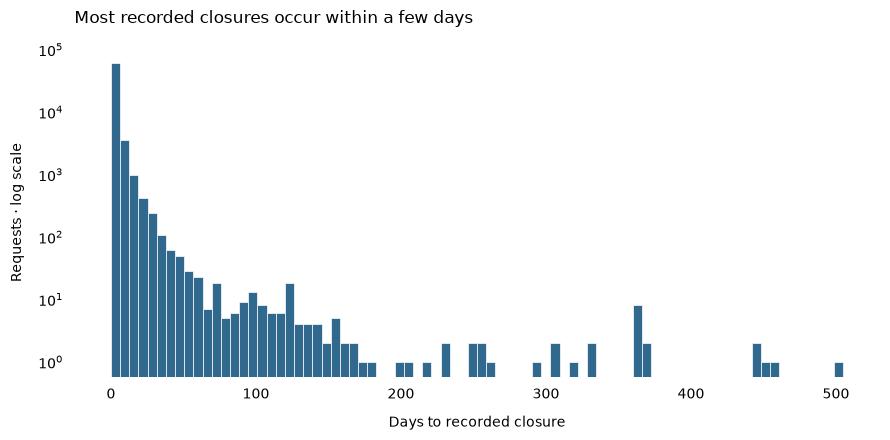

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 4.5))
valid_closed["closure_days"].hist(
    bins=80, grid=False, color="#31688e", edgecolor="white", linewidth=0.5
)
plt.yscale("log")
plt.title("Most recorded closures occur within a few days", loc="left", pad=18)
plt.xlabel("Days to recorded closure", labelpad=10)
plt.ylabel("Requests · log scale", labelpad=10)
plt.grid(False, which="both")
plt.tick_params(axis="both", which="both", length=0, pad=8)
for spine in plt.gca().spines.values():
    spine.set_visible(False)
plt.tight_layout()
plt.show()

The log count scale makes the sparse tail visible. The next view avoids histogram bins and shows the fraction of observed closed requests exceeding each duration. It is not a censoring-adjusted survival estimate; the final zero fraction is omitted because a log scale cannot display zero.

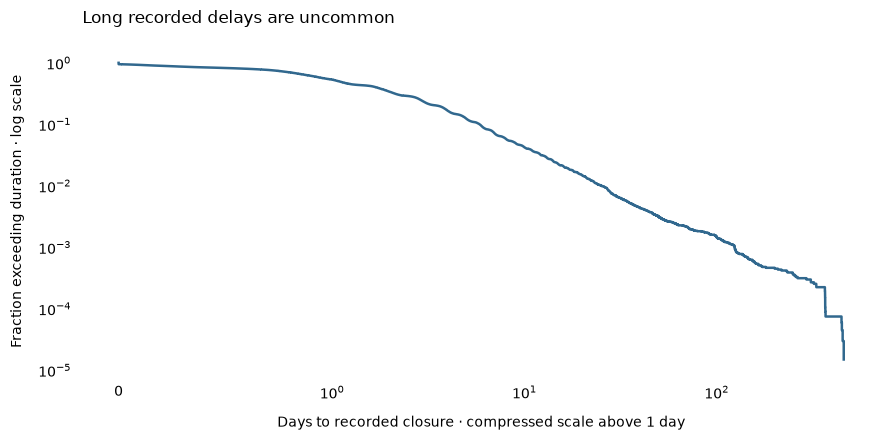

In [10]:
durations = valid_closed["closure_days"].sort_values()

plt.figure(figsize=(9, 4.5))
plt.step(
    durations.iloc[:-1],
    1 - pd.Series(range(1, len(durations))) / len(durations),
    where="post",
    color="#31688e",
    linewidth=1.8,
)
plt.xscale("symlog", linthresh=1)
plt.yscale("log")
plt.title("Long recorded delays are uncommon", loc="left", pad=18)
plt.xlabel("Days to recorded closure · compressed scale above 1 day", labelpad=10)
plt.ylabel("Fraction exceeding duration · log scale", labelpad=10)
plt.grid(False, which="both")
plt.tick_params(axis="both", which="both", length=0, pad=8)
for spine in plt.gca().spines.values():
    spine.set_visible(False)
plt.tight_layout()
plt.show()

## Inspecting long delays

The longest recorded delay is about 505 days. Keep extreme values unless a specific data error is established; unusual values alone are not a reason to remove them.

In [11]:
street.nlargest(10, "closure_days")[
    ["unique_key", "created_date", "closed_date", "closure_days"]
]

,unique_key,created_date,closed_date,closure_days
2552,63768188,2025-01-14 08:43:53,2026-06-03 11:09:57,505.101435
36095,65279946,2025-06-16 13:38:03,2026-09-16 11:11:41,456.898356
13075,64299875,2025-03-09 11:57:56,2026-06-03 11:25:18,450.977338
14293,64347547,2025-03-13 18:08:33,2026-06-03 11:45:45,446.734167
14639,64361067,2025-03-15 21:25:25,2026-06-03 15:45:57,444.764259
674,63652866,2025-01-04 23:12:14,2026-01-07 11:00:00,367.491505
9760,64194525,2025-02-24 07:09:49,2026-02-25 21:15:00,366.586933
33183,65172704,2025-06-04 13:31:18,2026-06-05 13:45:00,366.009514
155,63591833,2025-01-01 15:13:35,2026-01-02 11:25:00,365.841262
6119,63999287,2025-02-04 13:58:58,2026-02-05 09:30:00,365.813218


In [12]:
tail = valid_closed.loc[valid_closed["closure_days"] > 90]

print("closures after 90 days:", len(tail))
display(tail["closed_date"].dt.date.value_counts().head(10))
print(f"valid closed requests percent after 90 days: {len(tail)/len(valid_closed):.2%}")

closures after 90 days: 114


closed_date
2025-09-19    12
2026-06-03     4
2026-01-16     4
2025-11-14     3
2026-02-25     3
2025-12-02     3
2025-09-20     3
2025-07-03     3
2026-05-28     3
2025-07-29     3
Name: count, dtype: int64

valid closed requests percent after 90 days: 0.17%


Only 114 records, or 0.17% of valid closed requests, exceed 90 days. Some share closure dates, but this does not establish batch processing or the actual date work finished. The descriptive tail alone does not justify an extreme-value model.

## Checking what closure means

Compare status, closure-date presence, and the resolution text before treating any field as a completed-work outcome.

In [13]:
print("Missing closures:", street["closed_date"].isna().sum())

street.loc[street["closed_date"].isna(), "status"].value_counts(dropna=False)

Missing closures: 3477


status
Pending        3467
Open              8
Unspecified       2
Name: count, dtype: int64

In [14]:
pd.crosstab(
    street["status"].fillna("<missing>"),
    street["closed_date"].notna(),
).rename(columns={False: "No closure date", True: "Has closure date"})

closed_date,No closure date,Has closure date
status,,
Closed,0,66847
Open,8,0
Pending,3467,6
Unspecified,2,0


There are 3,477 requests without closure dates, mostly Pending. Six other requests are Pending despite having closure dates. These are separate from the six negative-duration records.

In [15]:
street["resolution_description"].value_counts(dropna=False).head(15).reset_index(name="requests")

,resolution_description,requests
0,The Department of Transportation inspected this complaint and repaired the problem.,27541
1,The Department of Transportation inspected and has requested the Department of Environmental Protection ad...,7750
2,The Department of Transportation inspected the condition you reported and found that the condition meets i...,5780
3,The Department of Transportation inspected the condition and issued a Corrective Action Repair (CAR) to th...,3759
4,The Department of Transportation inspected this complaint and did not find the reported problem.,3626
5,The Department of Transportation determined that this complaint is a duplicate of a previously filed compl...,3397
6,The Department of Transportation inspected the location for the condition you reported and could not find ...,2568
7,The Department of Transportation inspected the condition and issued a summons to the responsible party. A ...,2290
8,The Department of Transportation inspected the condition you reported. You can find additional information...,2231
9,The Department of Transportation referred this complaint to the Inspections Unit for further action.,1522


The common descriptions include reported repairs, referrals, enforcement, duplicates, and conditions not found. Closure is not a consistent measure of completed repair.

In [16]:
street.loc[
    street["closed_date"].notna() & street["status"].ne("Closed"),
    ["unique_key", "status", "created_date", "closed_date", "closure_days"],
]

,unique_key,status,created_date,closed_date,closure_days
82,63593137,Pending,2025-01-01 11:06:01,2025-01-02 07:50:00,0.863877
10124,64193620,Pending,2025-02-25 10:12:16,2025-02-25 22:00:00,0.491481
12219,64262821,Pending,2025-03-05 13:38:25,2025-03-06 00:11:00,0.439294
45108,65702641,Pending,2025-07-29 14:33:45,2025-07-31 14:30:00,1.997396
49663,65921670,Pending,2025-08-22 11:06:26,2025-08-22 11:06:26,0.000000
59168,66516407,Pending,2025-10-17 09:02:02,2025-10-17 09:02:02,0.000000


In [17]:
conflicts = street.loc[
    street["closed_date"].notna() & street["status"].ne("Closed"),
    ["unique_key", "status", "created_date", "closed_date", "closure_days", "resolution_description"],
]

for row in conflicts.itertuples(index=False):
    print(row.unique_key, row.status, row.closed_date)
    print(row.resolution_description, "\n")

63593137 Pending 2025-01-02 07:50:00
The Department of Transportation referred this complaint to the Inspections Unit for further action. 

64193620 Pending 2025-02-25 22:00:00
The Department of Transportation referred this complaint to the Inspections Unit for further action. 

64262821 Pending 2025-03-06 00:11:00
The Department of Transportation referred this complaint to the Inspections Unit for further action. 

65702641 Pending 2025-07-31 14:30:00
The Department of Transportation inspected this complaint and repaired the problem. 

65921670 Pending 2025-08-22 11:06:26
The Department of Transportation referred this complaint to the appropriate Maintenance Unit for repair. 

66516407 Pending 2025-10-17 09:02:02
The Department of Transportation referred this complaint to the Inspections Unit for further action. 



In [18]:
street.loc[
    street["closed_date"].isna(), "resolution_description"
].value_counts(dropna=False).head(20).reset_index(name="requests")

,resolution_description,requests
0,The Department of Transportation referred this complaint to the Inspections Unit for further action.,1516
1,The status of this Service Request is currently not available online. Please call 311 for further assistan...,1263
2,The Department of Transportation inspected this complaint and repaired the problem.,279
3,The Department of Transportation inspected this complaint and referred it to the Bridge Division for furth...,192
4,The Department of Transportation inspected this complaint and referred it to the Arterial Division for fur...,178
5,The Department of Transportation referred this complaint to the appropriate Maintenance Unit for repair.,26
6,NaN,14
7,The Department of Transportation inspected this complaint and found that the defect was not accessible. Th...,3
8,The Department of Transportation inspected this complaint and will schedule the repair.,2
9,The Department of Transportation inspected this complaint and found that the problem was fixed.,1


Among requests without closure dates, 279 descriptions report that DOT repaired the problem and one reports that the problem was already fixed. Of the six Pending requests with closure dates, five describe referrals and one reports repair.

These conflicts limit both fields: missing closure dates do not reliably identify unfinished repairs, and a closure date does not establish when physical work was completed. Resolution text helps interpret the outcome, but it is not independently verified and would not be used as an intake-time predictor.

DOT Street Condition is not selected as the primary cohort for repair-risk modeling. The EDA provides a reason to question the target before fitting a model, rather than treating an available timestamp as the outcome by default.

I will apply the same checks to DSNY Missed Collection, starting with its resolution descriptions and date consistency. It is a candidate for further analysis, not yet a validated alternative.